Website connected successfully!

Scraped Data:
                                           Book Name  Price  Rating  \
0                               A Light in the Attic  51.77       3   
1                                 Tipping the Velvet  53.74       1   
2                                         Soumission  50.10       1   
3                                      Sharp Objects  47.82       4   
4              Sapiens: A Brief History of Humankind  54.23       5   
5                                    The Requiem Red  22.65       1   
6  The Dirty Little Secrets of Getting Your Dream...  33.34       4   
7  The Coming Woman: A Novel Based on the Life of...  17.93       3   
8  The Boys in the Boat: Nine Americans and Their...  22.60       4   
9                                    The Black Maria  52.15       1   

  Availability  
0     In stock  
1     In stock  
2     In stock  
3     In stock  
4     In stock  
5     In stock  
6     In stock  
7     In stock  
8     In stock  
9

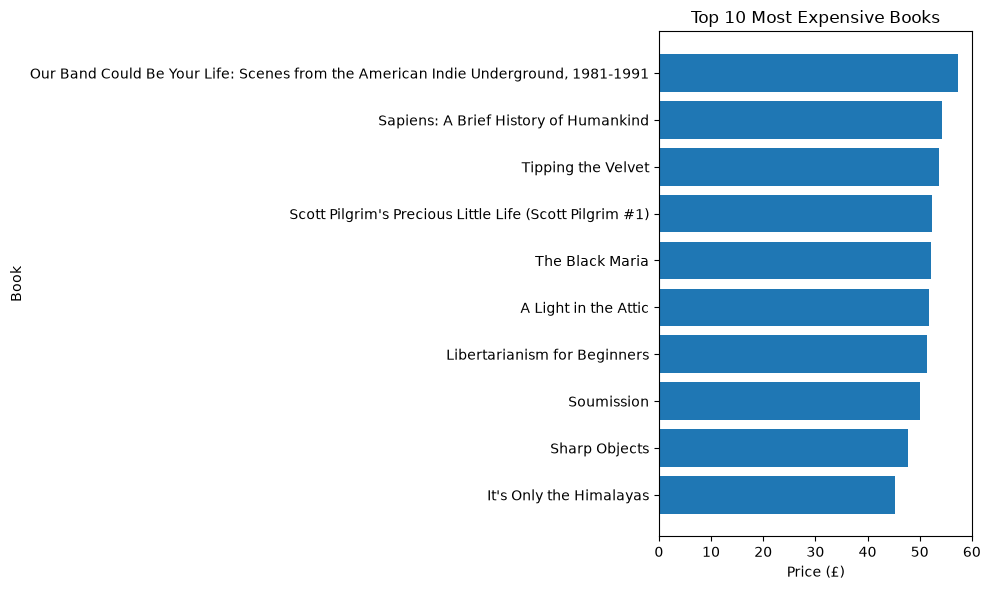

In [ ]:
# BookStore Data Scraper & Analyzer

import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt

# Website
url = "https://books.toscrape.com/"

# Send request
response = requests.get(url)

# Check response
if response.status_code == 200:
    print("Website connected successfully!")
else:
    print("Failed to connect:", response.status_code)
    exit()

# Parse HTML
soup = BeautifulSoup(response.text, "html.parser")

# Store scraped data
books = []

# Find all books
for book in soup.find_all("article", class_="product_pod"):

    # Book name
    name = book.h3.a["title"]

    # Price
    price = book.find("p", class_="price_color").text.strip()

    # Rating
    rating = book.find("p", class_="star-rating")["class"][1]

    # Availability
    availability = book.find(
        "p", class_="instock availability"
    ).text.strip()

    books.append({
        "Book Name": name,
        "Price": price,
        "Rating": rating,
        "Availability": availability
    })

# Create DataFrame
df = pd.DataFrame(books)

# Remove currency/encoding characters and convert prices to numbers
df["Price"] = pd.to_numeric(
    df["Price"].str.replace(r"[^0-9.]", "", regex=True)
)

# Convert rating into numbers
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating"] = df["Rating"].map(rating_map)

# Display data
print("\nScraped Data:")
print(df.head(10))

# Basic analysis
print("\nTotal Books:", len(df))

print("\nAverage Price:",
      round(df["Price"].mean(), 2))

print("\nAverage Rating:",
      round(df["Rating"].mean(), 2))

# Highest priced books
print("\nTop 5 Most Expensive Books:")
print(
    df.sort_values(
        by="Price",
        ascending=False
    )[["Book Name", "Price"]].head(5)
)

# Highest rated books
print("\nTop Rated Books:")
print(
    df[df["Rating"] == 5][
        ["Book Name", "Price", "Rating"]
    ]
)

# Save data
df.to_csv("scraped_books.csv", index=False)

print("\nData saved successfully as scraped_books.csv")

# Visualization
plt.figure(figsize=(10, 6))

top_books = df.sort_values(
    by="Price",
    ascending=False
).head(10)

plt.barh(
    top_books["Book Name"],
    top_books["Price"]
)

plt.xlabel("Price (£)")
plt.ylabel("Book")
plt.title("Top 10 Most Expensive Books")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()
